<p>
    <b>ADA Facility report</b><br>
    <b>Gulbenkian Institute for Molecular Medicine</b><br>
    <b>Oeiras, PT</b>
</p>
<br>

# **Setup**

## Database Import

Promoter sequences were retrieved from a local files of the reference genome and annotation from *Mus musculus* provided by RefSeq (version 27).

* `.gtf` and `.fasta` file - https://www.ncbi.nlm.nih.gov/datasets/genome/GCF_000001635.27/


The `pyranges` package is used (https://pyranges.readthedocs.io/en/latest/index.html) to work with the reference files

***

*Correction from the last report*: 

-1-
Ensembl/GENCODE annotation was originally used for uniformity with the RNA-seq analysis. However, this annotation's automated pipeline selects the "Canonical" transcript based on maximal exon and isoform support, which for some genes includes rare upstream non-coding exons — pushing the annotated TSS thousands of bp upstream of the functional promoter (Frankish et al., 2015). This was identified while confirming Bach1's regulation of Nqo1 (https://pmc.ncbi.nlm.nih.gov/articles/PMC2804160/), a directly-regulated target gene: the Ensembl-anchored promoter window did not correspond to the published, experimentally-validated ARE/promoter region. RefSeq annotation was therefore used instead, as its curated transcripts are more conservative and better track experimentally-supported transcription start sites.

Supporting references:
*https://pubmed.ncbi.nlm.nih.gov/24564364/ - When conducting research that emphasizes reproducible and robust gene expression estimates, a less complex genome annotation may be preferred.*
*https://pubmed.ncbi.nlm.nih.gov/35354358/ - the use of the conservative RefSeq gene annotation yields better RNA-seq quantification results than the more comprehensive Ensembl annotation*
*https://pmc.ncbi.nlm.nih.gov/articles/PMC4502323/ - (Regarding Ensembl) However, differences between the gene sets in terms of CDS length, reading frame or especially the presence or absence of the CDS could increase false positive reports, thus complicating interpretation.*

-2-
The project is now fully automated. The only remaining manual tasks are defining the gene list and verifying the transcription factor motifs to be searched. While the search of motif could also be automated in the future, manual verification is recommended, as some reported motifs lack sufficient specificity and may lead to a high number of false positives.

-3-
Several genes were not detected because the analysis required exact title formatting (e.g., Spic rather than SPIC or SpiC). Of the 35 genes provided by the user, 34 were successfully identified.
 

In [1]:
#| label: setup_packages_paths
#| code-fold: true
#| code-summary: "Setup: Imports and Reference File Paths"
#| output: false

# -------- data --------
import pyranges as pr
import pyfaidx                                  # FASTA indexing backend used by pr.get_sequence()
import pandas as pd
import numpy as np

# -------- cmd / files / strings --------
import os
import re
import subprocess
import tempfile
from pathlib import Path
from datetime import datetime

# -------- graph --------
import matplotlib.pyplot as plt
from PIL import Image                          # reads the CIS-BP logo PNGs

# -------- display --------
from IPython.display import display, Markdown, HTML
import session_info

# -------- Setting the Path for the necessary files -------- #
# Everything is derived from PROJECT, so moving the project only changes one line.
# str() is used for the reference files because they are handed to pyranges/pyfaidx.

PROJECT = Path("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder")
DATA    = PROJECT / "Data"
RESULTS = PROJECT / "Results"
RESULTS.mkdir(parents=True, exist_ok=True)

REFSEQ  = DATA / "ncbi_dataset_RefSeq_GCF_000001635.27"
GTF_v27 = str(REFSEQ / "genomic.gff")
FA_v27  = str(REFSEQ / "GCF_000001635.27_GRCm39_genomic.fna")

# written by the sequence-extraction cell, read back by every scan
PROMOTER_FASTA = RESULTS / "promoters_sequences.fasta"
PROMOTER_FASTA_5kb = RESULTS / "promoters_sequences_5kb.fasta"



In [2]:
#| label: gtf_import
#| code-fold: true
#| code-summary: "Import and Filter Reference GTF"
#| output: false
# -------- Reference GTF -------- #
gtf = pr.read_gff3(GTF_v27)                           # Import the GTF file, which has all the information necessary to extract the coordinates. Keep all attributes in single string
gtf_canonical = gtf[(gtf.Feature == "mRNA") & 
                     gtf.tag.str.contains("RefSeq Select", na=False)] 
   # Filter to include only transcripts that contain the tag "RefSeq Select" (curated to canonical transcripts)

## Promoter Gene Retrieval

A list of genes was given by the user to check for transcription factors motifs in the promoter:

* Transcription Factor genes: *Nfe2l2, SpiC, Bach1*;
* Regulation Network of SpiC: *Blvra, Hmox1, Vcam1, Slc40a1, Nqo1, Gsr, Slc7a11, Gclc, Cat, Gpx4, Gclm, Gss, Txnrd1, Fth1, Nfs1, Cisd1, Aifm2, Acsl4, Acsl2, LPCAT3, G6PDX, PGD, ME1, IDH1, Nox1, Elovl7, Ido1, ALAS1, DHODH, ACSL3, SCD1, SCD5*;
* Control gene of Bach1: *Nqo1*;

A few genes were found under another name in the genome used in this work:

* Acsl2 was found by the Acsl1 synonym name (https://www.uniprot.org/uniprotkb/P41216/entry);
* Aifm2 ws repeated in the list with FSP1 (AIFM2), it was found under Aifm2 (https://www.uniprot.org/uniprotkb/Q8BUE4/entry);
* There was no correspondence found for SCD5 in mice in this genome, nor in Uniprot.


The promoter region for each gene was defined as **−2,000 bp to +200 bp relative to the transcription start site (TSS)** of the canonical transcript. This interval was selected because it encompasses the proximal regulatory regions where transcription factor binding is most frequently observed.

More specifically:

* The **−2,000 bp upstream region** captures the proximal promoter and many of the cis-regulatory transcription factor binding sites.
* The **+200 bp downstream region** includes the TSS-proximal sequence, which often contains core promoter elements and regulatory motifs that overlap the transcription start site.
* The **TSS of the canonical transcript** was used as the reference coordinate to ensure a consistent and standardized definition of promoter regions across all analyzed genes.

These promoter sequences were subsequently used for transcription factor binding site analysis to evaluate the potential for direct SpiC-mediated transcriptional regulation, or indirect regulation through Nfe2l2-mediated transcriptional regulation.

### Extract transcript coordinates

In [3]:
#| label: gene_subset
#| code-fold: true
#| code-summary: "Select Canonical Transcripts for Genes of Interest"
#| output: asis
# List of genes of interest

#the gene name needs to be have a format with the first letter only in Caps to be found
genes = ["Spic", "Nfe2l2", "Bach1", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1", "Scd5", "Nqo1"]             

# NCBI RefSeq GFF3 uses "gene", not "gene_name" -- confirm via gtf_canonical.columns.tolist()
# before trusting this line if it comes back empty.
gtf_sub = gtf_canonical[gtf_canonical.gene.isin(genes)]
 
found = set(gtf_sub.df["gene"])
missing = set(genes) - found
 
print(f"{len(found)}/{len(set(genes))} genes found")

if missing:
    print(f"Missing: {sorted(missing)}")

print()
print(f"Are there duplicated values: {gtf_sub.df['gene'].duplicated().any()}")

34/35 genes found
Missing: ['Scd5']

Are there duplicated values: False


Register the Start & End coordinates of the transcript

In [4]:
#| label: gtf_sub_preview
#| code-fold: true
#| code-summary: "Selected Transcript Coordinates"
#| output: asis
gtf_sub[['Chromosome', 'gene', 'transcript_id', 'Source', 'Feature', 'Start', 'End', 'Strand']]    # Inspect the selected canonical transcripts (one per gene of interest)

/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])
/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])


,Chromosome,gene,transcript_id,Start,End,Strand,Source,Feature
0,NC_000067.7,Acsl3,NM_001033606.3,78635599,78685462,+,BestRefSeq,mRNA
1,NC_000067.7,Slc40a1,NM_016917.2,45947229,45964754,-,BestRefSeq,mRNA
2,NC_000067.7,Idh1,NM_010497.3,65197774,65218301,-,BestRefSeq,mRNA
3,NC_000068.8,Blvra,NM_026678.4,126912576,126939004,+,BestRefSeq,mRNA
4,NC_000068.8,Nfe2l2,NM_010902.5,75505859,75534860,-,BestRefSeq,mRNA
5,NC_000068.8,Cat,NM_009804.2,103284248,103315498,-,BestRefSeq,mRNA
6,NC_000068.8,Gss,NM_008180.2,155405100,155434730,-,BestRefSeq,mRNA
7,NC_000068.8,Nfs1,NM_010911.3,155965568,155986106,-,BestRefSeq,mRNA
8,NC_000069.7,Gclm,NM_008129.4,122039205,122060864,+,BestRefSeq,mRNA
9,NC_000069.7,Slc7a11,NM_011990.2,50319384,50398062,-,BestRefSeq,mRNA


Plus strand (+): transcription goes left→right along the reference. The biological start (TSS, 5′ end) is at Start, and the 3′ end is at End.

Minus strand (-): transcription goes right→left along the reference. The biological start (TSS, 5′ end) is at End, and the 3′ end is at Start.

### Extract promoter coordinates

Register the Start & End coordinates. 

* In the *strand -* the TSS is at the `End` coordinate of the transcript. Therefore the start of the promoter should be +2000bp from `End` in `gtf_sub`/transcript (Start of the promoter is in the `End` coordinate of the promoter),  and -200bp (End of the promoter is in the `Start` coordinate of the promoter). 

* In the *strand +* the TSS is at the `Start` coordinate of the transcript. Therefore the promoter should `Start` -2000bp from `Start` in `gtf_sub`/transcript (Start of the promoter is in the `Start` coordinate of the promoter),  and  +200bp (End of the promoter is in the `End` coordinate of the promoter). 



In [5]:
#| label: promoter_coords
#| code-fold: true
#| code-summary: "Compute 2 kb Promoter Coordinates"
#| output: true

# five_end(): collapses each interval to its single TSS coordinate (strand-aware --
#             gene Start on +, gene End on -), giving a 1bp interval at the TSS.
# .slack({"5": 2000, "3": 200}): extends that TSS point strand-aware:
#             2000bp toward the 5' side (upstream) and 200bp toward the 3' side
#             (downstream), so the result is your -2000/+200 promoter window
#             regardless of which genomic strand the gene is on.
prom_2kb = gtf_sub.five_end().slack({"5": 2000, "3": 200}) 
prom_2kb[['gene','transcript_id','Start', 'End', 'Strand']]                            

/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])
/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])


,Chromosome,Start,End,Strand,gene,transcript_id
0,NC_000067.7,78633599,78635800,+,Acsl3,NM_001033606.3
1,NC_000067.7,45964553,45966754,-,Slc40a1,NM_016917.2
2,NC_000067.7,65218100,65220301,-,Idh1,NM_010497.3
3,NC_000068.8,126910576,126912777,+,Blvra,NM_026678.4
4,NC_000068.8,75534659,75536860,-,Nfe2l2,NM_010902.5
5,NC_000068.8,103315297,103317498,-,Cat,NM_009804.2
6,NC_000068.8,155434529,155436730,-,Gss,NM_008180.2
7,NC_000068.8,155985905,155988106,-,Nfs1,NM_010911.3
8,NC_000069.7,122037205,122039406,+,Gclm,NM_008129.4
9,NC_000069.7,50397861,50400062,-,Slc7a11,NM_011990.2


## Extract sequences based on the coordinates

In [6]:
#| label: extract_sequences
#| code-fold: true
#| code-summary: "Extract Promoter Sequences from Reference"
#| output: false

seqs_2kb = pr.get_sequence(prom_2kb, path=FA_v27)                        # Based on the coordinates identified before, we get the sequences from the reference genome
#get_sequence is also strand-aware and reverse-complements the minus strand

df_2kb                 = seqs_2kb.to_frame(name="DNA_Sequence")   # Convert the extracted sequences into a dataframe
df_2kb["Gene_Name"]    = prom_2kb.df['gene']                 # Attach gene names for use in the FASTA headers
df_2kb["TranscriptID"] = prom_2kb.df["transcript_id"]             # Attach transcript IDs for use in the FASTA headers

with open(PROMOTER_FASTA, "w") as file:
    for index, row in df_2kb.iterrows():
        # Combine your metadata into a single header line
        header = f">{row['Gene_Name']}|{row['TranscriptID']}"
        
        # Write the header and the sequence
        file.write(f"{header}\n")
        file.write(f"{row['DNA_Sequence']}\n")

Saved in *promoters_sequences.fasta*.

## Retrieve Transcription Factors Motifs

Position-specific scoring matrices were taken from the **CIS-BP** *Mus musculus*
collection (Build 3.10, https://cisbp.ccbr.utoronto.ca), downloaded in bulk and
stored under `Data/`.

CIS-BP may contain multiple motif models for the same transcription factor, often derived from different studies or experimental approaches. Therefore, the motif matrices selected for analysis should be curated manually. Some motifs are relatively nonspecific and can generate numerous weakly supported matches. This was the case of SpiC motif `M01562_3.00`.

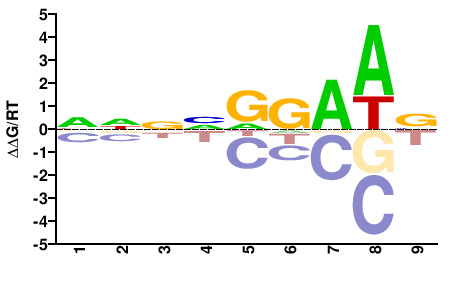

To ensure reproducibility, the motif accessions used in this analysis are listed explicitly in the `MOTIFS` section below: `M03221_3.10` for SpiC; `M09222_3.10` and `M10174_3.10` for Nfe2l2; and `M10181_3.10` for Bach1. These accession identifiers document exactly which position weight matrices were scanned during the analysis.


In [7]:
#| label: rsat_setup
#| code-fold: true
#| code-summary: "Setup: paths and scan parameters"
#| output: false
 
# paths and variables
 
SCAN_DIR = RESULTS / "matrix_scan"
SCAN_DIR.mkdir(parents=True, exist_ok=True)
RSAT_ENV = Path("/srv/ext_home/ssalazar/.conda/envs/rsat")
 
MARKOV_ORDER = 1        # background order; oligo length k = order + 1
PVAL         = 1e-4
TSS_OFFSET   = 201      # -origin end places the TSS at -201
 
# rsat is a Perl script: its env's bin must lead PATH, or the shebang picks base's perl
ENV = os.environ | {"PATH": f"{RSAT_ENV / 'bin'}{os.pathsep}{os.environ['PATH']}",
                     "RSAT": str(RSAT_ENV / 'share' / 'rsat'),
                     "CONDA_PREFIX": str(RSAT_ENV)}
 
 
def rsat(tool, *args):
    # some tools report errors on stdout while exiting 0
    cmd = [str(RSAT_ENV / "bin" / "rsat"), tool, *map(str, args)]
    p = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
    out = p.stderr + p.stdout
    if p.returncode or re.search(r"^Error", out, re.M):
        raise RuntimeError(" ".join(cmd) + "\n" + out)
    return out
 
 
def read_fasta(path):
    # [(header, sequence), ...], headers keep their '>'
    # used for counting/subsetting only, so no Biopython dependency;
    # `cur is not None` (not `cur`) so a header right after another header
    # doesn't swallow the next record's lines
    recs, cur = [], None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            cur = [line, []]
            recs.append(cur)
        elif cur is not None:
            cur[1].append(line.strip())
    return [(h, "".join(s)) for h, s in recs]
 
 

  M03221_3.10    14 bp -> Spic


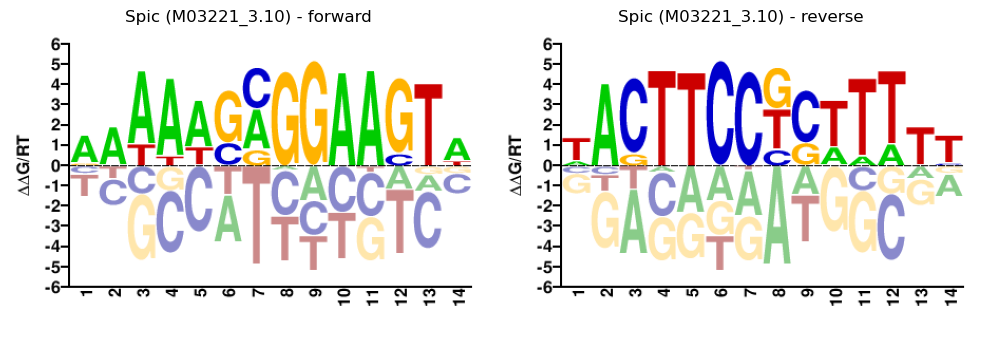

  M09222_3.10    11 bp -> Nfe2l2_1


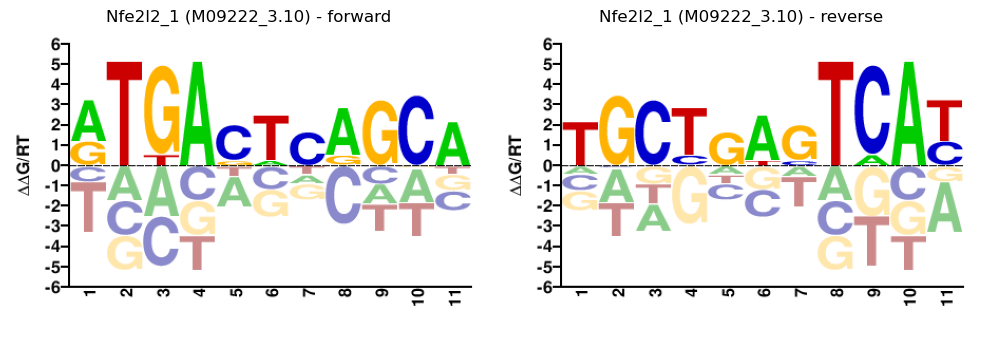

  M10174_3.10    14 bp -> Nfe2l2_2


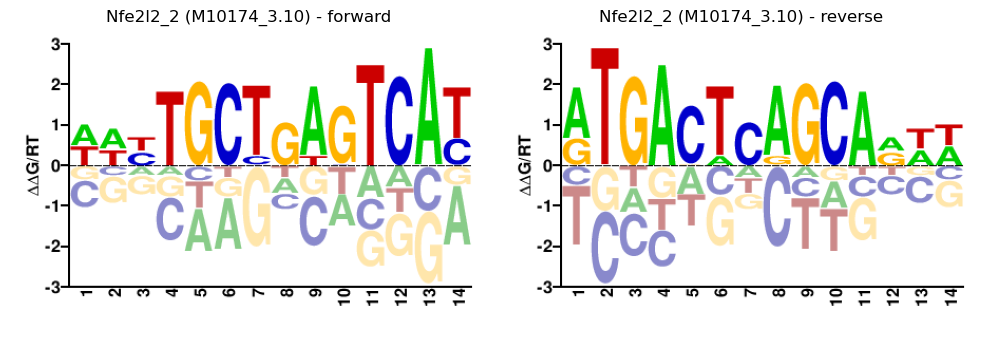

  M10181_3.10    14 bp -> Bach1


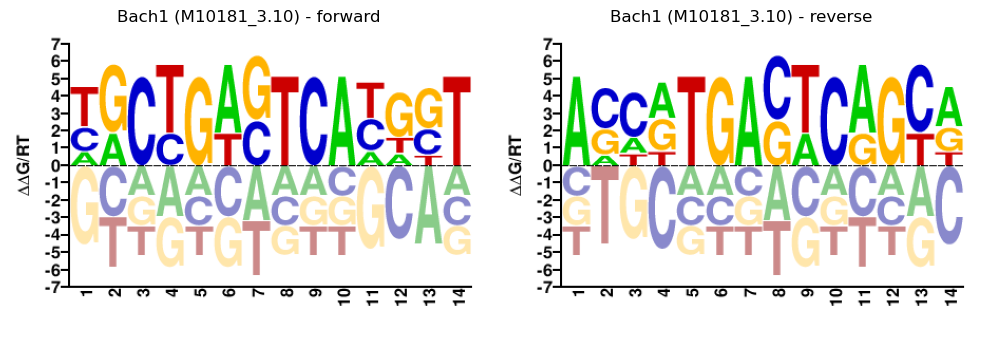


4 matrices saved in motif_matrices_SpiC_Nfe2l2_Bach1.tf


In [8]:
#| label: tf_matrices
#| code-fold: true
#| code-summary: "transcription factor matrices"
#| output: asis
 
CISBP = DATA / "Mus_musculus_2026_09_17_11_49_am_CISBP"
 
# motif accession -> name to use in the ft_name column of the scan
# looked up once in TF_Information.txt, then hard-coded here
MOTIFS = {"M03221_3.10": "Spic",
          "M09222_3.10": "Nfe2l2_1",
          "M10174_3.10": "Nfe2l2_2",
          "M10181_3.10": "Bach1"}
 
# color dictionary for consistency across plots (npg / Nature Publishing Group palette)
MOTIF_COLORS = {"Spic":     "#E64B35",
                 "Nfe2l2_1": "#4DBBD5",
                 "Nfe2l2_2": "#00A087",
                 "Bach1":    "#3C5488"}

blocks = []
for acc, label in MOTIFS.items():
    m = pd.read_csv(CISBP / "pwms_all_motifs" / f"{acc}.txt", sep="\t")
 
    # CIS-BP gives probabilities (rows sum to 1); x100 makes them count-like, so
    # matrix-scan's -pseudo 1 stays a small correction instead of half the column
    rows = [f"{i:02d}\t" + "\t".join(f"{v * 100:.4f}" for v in r)
            for i, r in enumerate(m[["A", "C", "G", "T"]].values, start=1)]
 
    blocks.append(f"AC  {acc}\nXX\nID  {label}\nXX\nDE  {label}\n"
                   "P0\tA\tC\tG\tT\n" + "\n".join(rows) + "\nXX\n//\n")
    print(f"  {acc:<14} {len(m)} bp -> {label}")

    # Show the CIS-BP logo of the matrix actually scanned, both orientations, so the
    # report records what each matrix looks like and not only its accession.
    ifw  = Image.open(CISBP / "logos_used_motifs" / f"{acc}_fwd.png")
    irev = Image.open(CISBP / "logos_used_motifs" / f"{acc}_rev.png")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(ifw)
    axes[0].set_title(f"{label} ({acc}) - forward")
    axes[0].axis("off")
    axes[1].imshow(irev)
    axes[1].set_title(f"{label} ({acc}) - reverse")
    axes[1].axis("off")
    plt.tight_layout()
    fig.savefig(SCAN_DIR / f"motif_logo_{label}.svg", format="svg", bbox_inches="tight")
    plt.show()
 
MATRIX = SCAN_DIR / "motif_matrices_SpiC_Nfe2l2_Bach1.tf"
MATRIX.write_text("".join(blocks))
print(f"\n{len(blocks)} matrices saved in {MATRIX.name}")

# **Search of Motifs in the Promoter Regions**

Motif scanning was performed with the **Regulatory Sequence Analysis Tools (RSAT)** suite to assess the presence of **SpiC**, **Nfe2l2** and **Bach1** transcription factor binding motifs within the retrieved promoter sequences. Detection of these motifs provides preliminary evidence for potential direct regulatory interactions between the transcription factors and their target genes.

The background model is a **first-order Markov chain estimated from the input promoter set**: because a Position-Specific Scoring Matrices treats positions independently, dinucleotide composition is accounted for solely in the background term, and the SpiC motif consists largely of purine-purine steps that are over-represented in mouse genomic sequence. An order-0 model would not represent this and would assign such matches anti-conservative *P*-values.

*Changes from last report*:

The *matrix-scan* tool reports individual motif occurrences that pass a per-site significance threshold of *P* < 1 × 10⁻⁴ within each promoter sequence. In this workflow, the scan is executed directly from the notebook using a local **RSAT** installation (`rsat-core`, Bioconda), replacing the manual web-based procedure previously described in **SOP RSAT Tools - Part 2**. Running the analysis within the notebook ensures that the motif matrices, background model, and significance thresholds are fully documented in the report itself rather than being captured in screenshots. This approach improves reproducibility, provides complete traceability of the analysis parameters, and makes the workflow easier to adapt to new transcription factors, gene sets, or scanning criteria. 



In [9]:
#| label: rsat_scan
#| code-fold: true
#| code-summary: "Background model and matrix-scan"
#| output: false
 
def scan(motifs, genes=None, pval=PVAL, name=None, bg_from="input", MATRIX = MATRIX, FASTA=None):
    # motifs: list of ft_name labels, e.g. ['Spic', 'Bach1']
    # genes: list of gene names; None scans all promoters
    # only the .ft.txt is kept

    out = SCAN_DIR / f"scanmotif_{name}.ft"

    # matrix subset, promoter subset and background model are RSAT inputs, so they're
    # written to a temp dir removed on return; still recoverable from the ';' header of
    # the .ft.txt, which records the matrix, pseudo-counts and residue probabilities
    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
 
        # requested matrices only, from motif_matrices_SpiC_Nfe2l2_Bach1.tf
        blocks = [b.strip() + "\n//\n" for b in MATRIX.read_text().split("//")
                  if (m := re.search(r"^ID\s+(\S+)\s*$", b, re.M))
                  and m.group(1) in motifs]
        assert len(blocks) == len(motifs), f"matrix not found, wanted {motifs}"
        mat = tmp / "matrices.tf"
        mat.write_text("".join(blocks))
 
        # requested promoters only; genes=None keeps all
        recs = [(i, s) for i, s in read_fasta(FASTA)
                if not genes or any(g.lower() in i.lower() for g in genes)]
        assert recs, f"no promoter matched {genes}"
        seqs = tmp / "promoters.fasta"
        seqs.write_text("".join(f">{i}\n{s}\n" for i, s in recs))
 
        # background is always estimated from the FULL promoter set, never the gene
        # -bginput / create-background-model fail in this build (rsat-core 2025.04.04,
        # bioconda) at every Markov order ("the sum must be strictly positive", then a
        # division by zero in RSAT/matrix.pm), so the model is estimated with
        # oligo-analysis and passed via -bgfile instead: same estimator, same sequences.
        # -1str matches the web run, whose residue probabilities are strand-asymmetric.
        # verified against the web run: 62/63 sites, same 20 promoters, marginals to 3 decimals
        bg = tmp / "bg.tab"
        bg_src = FASTA if bg_from == "all" else seqs
        rsat("oligo-analysis", "-i", bg_src, "-l", MARKOV_ORDER + 1, "-1str",
             "-return", "occ,freq", "-o", bg)
 
        # -origin end keeps positions negative from the sequence end (TSS at -TSS_OFFSET)
        # -2str reports D/R, combined with transcript strand downstream
        # -return limits gives the START_END rows used for promoter extents
        rsat("matrix-scan", "-v", 1,
             "-i", seqs, "-seq_format", "fasta",
             "-m", mat, "-matrix_format", "transfac",
             "-bgfile", bg, "-bg_pseudo", 0.01, "-pseudo", 1,
             "-2str", "-origin", "end", "-n", "score",
             "-return", "limits", "-return", "sites", "-return", "pval",
             "-uth", "pval", pval, "-o", out)
 
    hits = pd.read_csv(out, sep="\t", comment=";").query("ft_type == 'site'")
    hits.attrs["scan_path"] = out
    print(f"{len(recs)} promoters, {len(motifs)} matrices, "
          f"{len(hits)} sites at P < {pval:g}")
   
    return hits

In [10]:
#| label: sitemap_function
#| code-fold: true
#| code-summary: "Site map figure function"
#| output: false

def sitemap(hits, name=None, pval=PVAL, MOTIF_COLORS = MOTIF_COLORS):
    """Map motif sites along each promoter, positions relative to the TSS.

    hits  the DataFrame returned by scan(); its .attrs['scan_path'] is re-read to
          recover the 'limit' rows, so promoters with no site still get a lane.
    """
    
    path = Path(hits.attrs["scan_path"])
    lim  = (pd.read_csv(path, sep="\t", comment=";").query("ft_type == 'limit'")
              .drop_duplicates("#seq_id").set_index("#seq_id"))

    h = hits.assign(tss_pos=hits[["start", "end"]].mean(axis=1) + TSS_OFFSET,
                    logp=-np.log10(hits["Pval"]))
    ypos   = {s: i for i, s in enumerate(lim.index)}
    colors = {m: MOTIF_COLORS.get(m, "0.4") for m in h["ft_name"].unique()}

    fig, ax = plt.subplots(figsize=(9, 0.33 * len(lim) + 1.5))
    ax.hlines(range(len(lim)), lim["start"] + TSS_OFFSET, lim["end"] + TSS_OFFSET,
              color="0.87", lw=3.5, zorder=1)

    # Size scales with significance from the threshold up; label once per motif,
    # on the direct strand, so the legend shows colour rather than colour x strand.
    for (motif, strand), g in h.groupby(["ft_name", "strand"]):
        ax.scatter(g["tss_pos"], g["#seq_id"].map(ypos),
                   marker="v" if strand == "R" else "^",
                   s=50 + 200 * (g["logp"] + np.log10(pval)) / 3,
                   color=colors[motif], zorder=3, alpha=0.85,
                   edgecolors="white", linewidths=0.4,
                   label=motif if strand == "D" else None)

    ax.axvline(0, color="crimson", lw=1, ls="--", zorder=2)
    ax.text(0, -0.65, " TSS", color="crimson", va="top", fontsize=8)
    ax.set_yticks(range(len(lim)))
    ax.set_yticklabels([s.lstrip(">").split("|")[0] for s in lim.index], fontsize=10)
    ax.set_ylim(-0.7, len(lim) - 0.3); ax.invert_yaxis()
    ax.set_xlabel("position relative to TSS (bp)")
    ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,
              markerscale=0.8, loc="upper left", bbox_to_anchor=(1.01, 1),
              frameon=False)
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout(rect=[0, 0, 0.85, 1])

    fig_path = SCAN_DIR / f"sitemap_{name}.svg"
    fig.savefig(fig_path)
  
    return fig

## SpiC Motifs in the SpiC Network Genes Promoters

32 promoters, 1 matrices, 26 sites at P < 0.0001


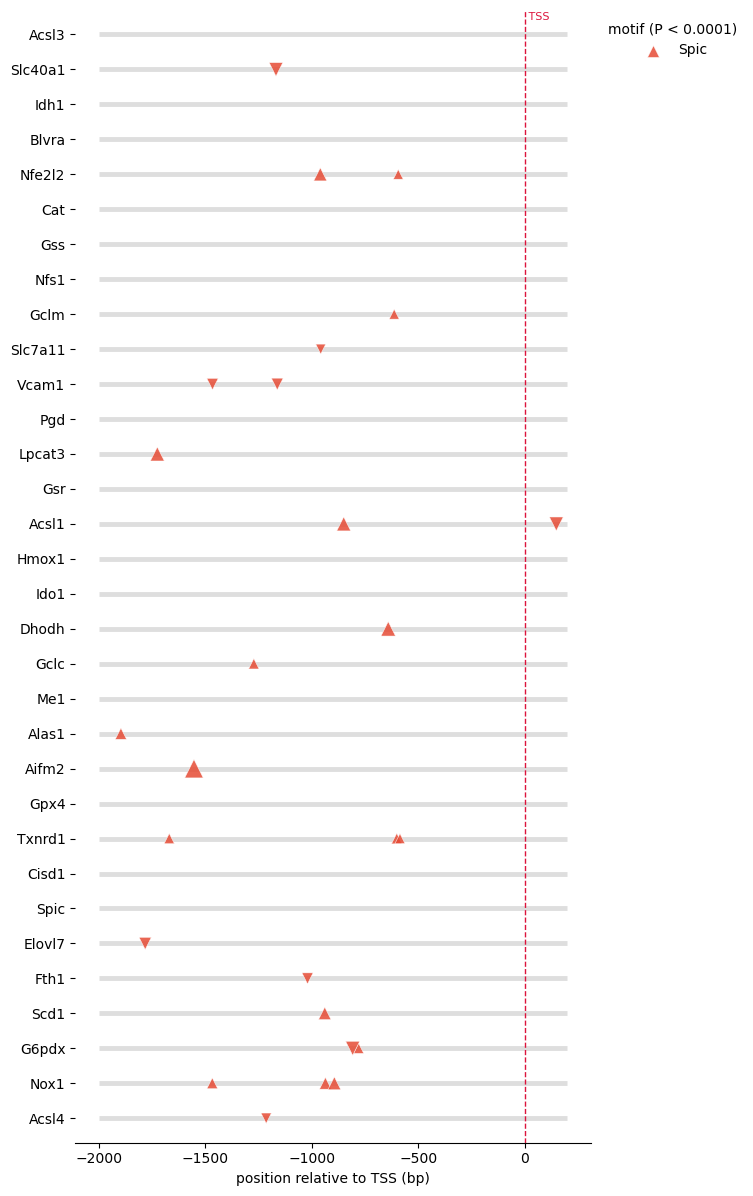

In [11]:
#| label: spicnetwork_spic_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network SpiC Motifs Map"
#| output: asis
#| column: page

# Scan the 30 SpiC-network promoters with the SpiC matrix only, then draw the site map.
hits_SpiCnet_SpiCmotif = scan(["Spic"], genes=["Spic","Nfe2l2", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiC_network_SpiCmotif', FASTA = PROMOTER_FASTA)             

graph_SpiCnet_SpiCmotif = sitemap(hits_SpiCnet_SpiCmotif, name='SpiC_network_SpiCmotif')

In [12]:
#| label: rsat_spic_load
#| code-fold: true
#| code-summary: "Load and Clean RSAT Motif Hits (SpiC Network)"
#| output: false

def process_motif_hits(name, hits_df, gtf_sub):

        # prepare data from RSAT tools
        sites = hits_df[hits_df["ft_type"] == "site"].copy()   # drop the 'limit' (START_END) rows, not significant
        sites[["Gene_Name", "TranscriptID"]] = sites["#seq_id"].str.split("|", expand=True)  # seq_id = Gene_Name|TranscriptID
        sites["Gene_Name"] = sites["Gene_Name"].str.strip('>')

        sites_filtered = sites[['Gene_Name', 'TranscriptID', 'sequence', 'start', 'end', 'strand', 'Pval', 'sig']].copy()
        sites_filtered = sites_filtered.rename(columns={'sequence': 'Motif_Sequence_Found',
                                                        'start':   "start_motif_pos_promoter",   # 1-based TSS base
                                                        'end':     "end_motif_pos_promoter",
                                                        'strand':  "strand_motif"})

        # get transcript metadata + TSS (from five_end(), 1-based, strand dependent), merge in one go
        meta = (gtf_sub.df[["Chromosome", "Strand", "transcript_id"]]
                .rename(columns={"Strand": "Chromosome_Strand", "transcript_id": "TranscriptID"})
                .merge(gtf_sub.five_end().df[["transcript_id", "End"]]
                        .rename(columns={"End": "TSS_chromosomal_localization", "transcript_id": "TranscriptID"}),
                        on="TranscriptID", how="left"))

        sites_filtered = sites_filtered.merge(meta, on="TranscriptID", how="left")

        # transcript-relative edges: 0 = TSS base, + = downstream (origin=end anchor at -201)
        sites_filtered["start_motif_pos_promoter"] += TSS_OFFSET
        sites_filtered["end_motif_pos_promoter"]   += TSS_OFFSET

        # nearest edge: end if upstream, start if downstream, 0 if it straddles the TSS
        sites_filtered["dist_to_TSS"] = np.where(
        sites_filtered["end_motif_pos_promoter"] < 0, sites_filtered["end_motif_pos_promoter"],
        np.where(sites_filtered["start_motif_pos_promoter"] > 0, sites_filtered["start_motif_pos_promoter"], 0),
        )

        # to genome (1-based): + adds, - subtracts (edges swap so start <= end)
        plus = sites_filtered["Chromosome_Strand"].eq("+")
        TSS  = sites_filtered["TSS_chromosomal_localization"]
        start = np.where(plus, TSS + sites_filtered["start_motif_pos_promoter"], TSS - sites_filtered["end_motif_pos_promoter"])
        end   = np.where(plus, TSS + sites_filtered["end_motif_pos_promoter"],   TSS - sites_filtered["start_motif_pos_promoter"])

        sites_filtered["motif_genomic_localization"] = start.astype(int).astype(str) + "-" + end.astype(int).astype(str)
        sites_filtered["motif_genomic_strand"] = np.where(plus == sites_filtered["strand_motif"].eq("D"), "+", "-")

        sites_filtered.drop(columns=["strand_motif"], inplace=True)

        sites_filtered.to_csv(RESULTS / f"motifs_coordinates_{name}.csv", index=False)
        return sites_filtered

In [13]:
#| label: spicnetwork_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network Motif Coordinates"
#| output: asis

# Map the SpiC hits back to genomic coordinates and write the CSV.
spic_network_motifs_table = process_motif_hits("SpiC_network_SpiCmotif", hits_SpiCnet_SpiCmotif, gtf_sub)
spic_network_motifs_table   # Inspect the SpiC-network motif hits mapped to genomic coordinates


,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promoter,end_motif_pos_promoter,Pval,sig,Chromosome,Chromosome_Strand,TSS_chromosomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Slc40a1,NM_016917.2,AAAATGGGGTAGTA,-1174,-1161,0.000020,4.689,NC_000067.7,-,45964754,-1161,45965915-45965928,+
1,Nfe2l2,NM_010902.5,AAATAGAGTAAGTA,-966,-953,0.000025,4.606,NC_000068.8,-,75534860,-953,75535813-75535826,-
2,Nfe2l2,NM_010902.5,CAAATCAGGGAGTG,-600,-587,0.000099,4.005,NC_000068.8,-,75534860,-587,75535447-75535460,-
3,Gclm,NM_008129.4,GGAATGGGGAAGAA,-619,-606,0.000094,4.026,NC_000069.7,+,122039206,-606,122038587-122038600,+
4,Slc7a11,NM_011990.2,CAAAGCCGGAAATT,-964,-951,0.000094,4.026,NC_000069.7,-,50398062,-951,50399013-50399026,+
5,Vcam1,NM_011693.3,CAACAGAGGAAGTG,-1472,-1459,0.000054,4.268,NC_000069.7,-,115923337,-1459,115924796-115924809,+
6,Vcam1,NM_011693.3,ATAAAAGGGAAGTT,-1168,-1155,0.000046,4.340,NC_000069.7,-,115923337,-1155,115924492-115924505,+
7,Lpcat3,NM_145130.3,AGCATGAGGAAGTA,-1731,-1718,0.000017,4.776,NC_000072.7,+,124640091,-1718,124638360-124638373,+
8,Acsl1,NM_007981.5,ATATTGCGGAAGTC,-856,-843,0.000017,4.776,NC_000074.7,+,46924214,-843,46923358-46923371,+
9,Acsl1,NM_007981.5,GAAAAGCGGAACGT,142,155,0.000018,4.748,NC_000074.7,+,46924214,142,46924356-46924369,-


## Analysis of Transcription Factors Cross-regulation

### Nfe2l2 Regulation

32 promoters, 2 matrices, 49 sites at P < 0.0001


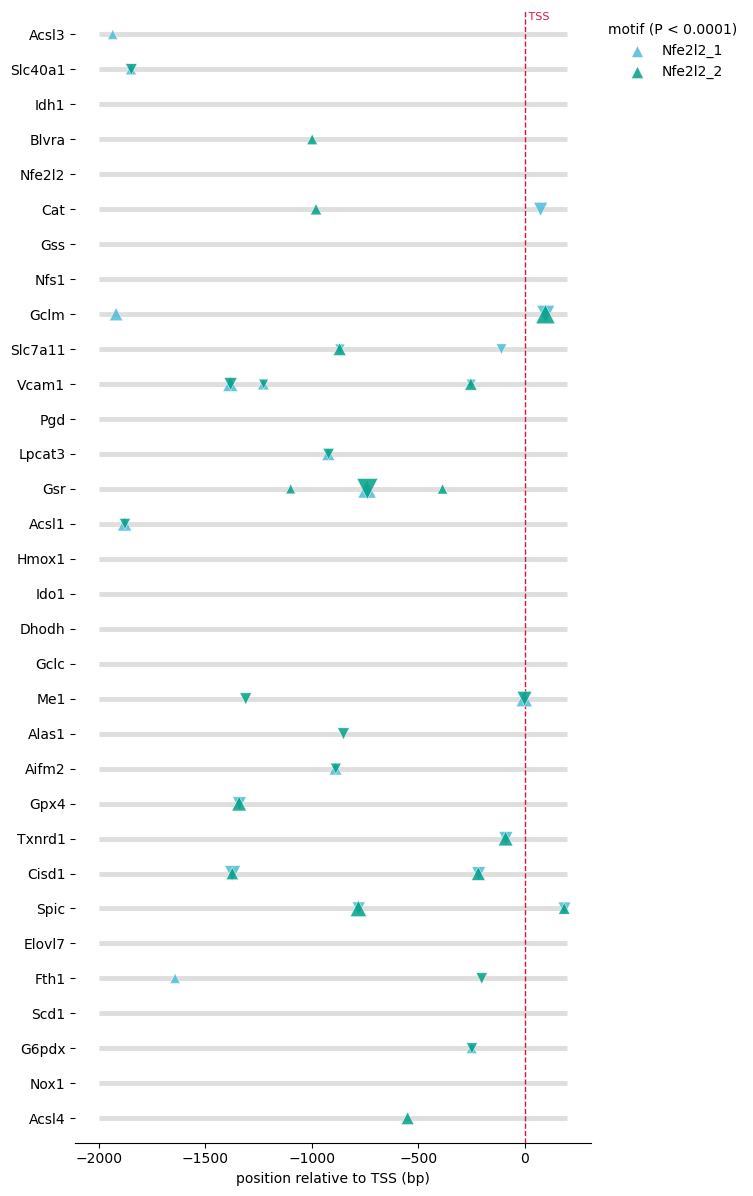

In [14]:
#| label: spicnetwork_Nfe2l2_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network Nfe2l2 Motifs Map"
#| output: asis
#| column: page

# Same 30 promoters, scanned with both Nfe2l2 matrices.
hits_SpiCnet_Nfe2l2motif = scan(["Nfe2l2_1", "Nfe2l2_2"], genes=["Spic","Nfe2l2", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiC_network_Nfe2l2motif', FASTA = PROMOTER_FASTA)             

graph_SpiCnet_Nfe2l2motif = sitemap(hits_SpiCnet_Nfe2l2motif, name="SpiC_network_Nfe2l2motif")

In [15]:
#| label: spicnetwork_nfe2l2_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network Nfe2l2 Motifs Table"
#| output: asis

# Map the Nfe2l2 hits back to genomic coordinates and write the CSV.
spic_network_Nfe2l2motif_table = process_motif_hits("SpiC_network_Nfe2l2motif", hits_SpiCnet_Nfe2l2motif, gtf_sub)
spic_network_Nfe2l2motif_table

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promoter,end_motif_pos_promoter,Pval,sig,Chromosome,Chromosome_Strand,TSS_chromosomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Acsl3,NM_001033606.3,GTGAGTCATCA,-1939,-1929,9.100000e-05,4.041,NC_000067.7,+,78635600,-1929,78633661-78633671,+
1,Slc40a1,NM_016917.2,GTGACTGAGCT,-1853,-1843,6.700000e-05,4.171,NC_000067.7,-,45964754,-1843,45966597-45966607,-
2,Slc40a1,NM_016917.2,CATAGCTCAGTCAC,-1853,-1840,5.400000e-05,4.271,NC_000067.7,-,45964754,-1840,45966594-45966607,+
3,Blvra,NM_026678.4,TATGGCTTATTCAT,-1004,-991,7.300000e-05,4.135,NC_000068.8,+,126912577,-991,126911573-126911586,+
4,Cat,NM_009804.2,ATGTCCTCAGTCAC,-986,-973,5.900000e-05,4.226,NC_000068.8,-,103315498,-973,103316471-103316484,-
5,Cat,NM_009804.2,GTGAGACAGCA,70,80,1.800000e-05,4.739,NC_000068.8,-,103315498,70,103315418-103315428,+
6,Gclm,NM_008129.4,ATGACTTTGCA,-1923,-1913,2.400000e-05,4.621,NC_000069.7,+,122039206,-1913,122037283-122037293,+
7,Gclm,NM_008129.4,TTCTGCTTAGTCAT,91,104,7.100000e-07,6.146,NC_000069.7,+,122039206,91,122039297-122039310,+
8,Gclm,NM_008129.4,ATGACTAAGCA,94,104,2.100000e-06,5.673,NC_000069.7,+,122039206,94,122039300-122039310,-
9,Slc7a11,NM_011990.2,ATATGCCCTGTCAT,-875,-862,3.100000e-05,4.511,NC_000069.7,-,50398062,-862,50398924-50398937,-


### Bach1 Regulation

#### Bach1 Regulation of SpiC network, plus Nqo1 as control

32 promoters, 1 matrices, 18 sites at P < 0.0001


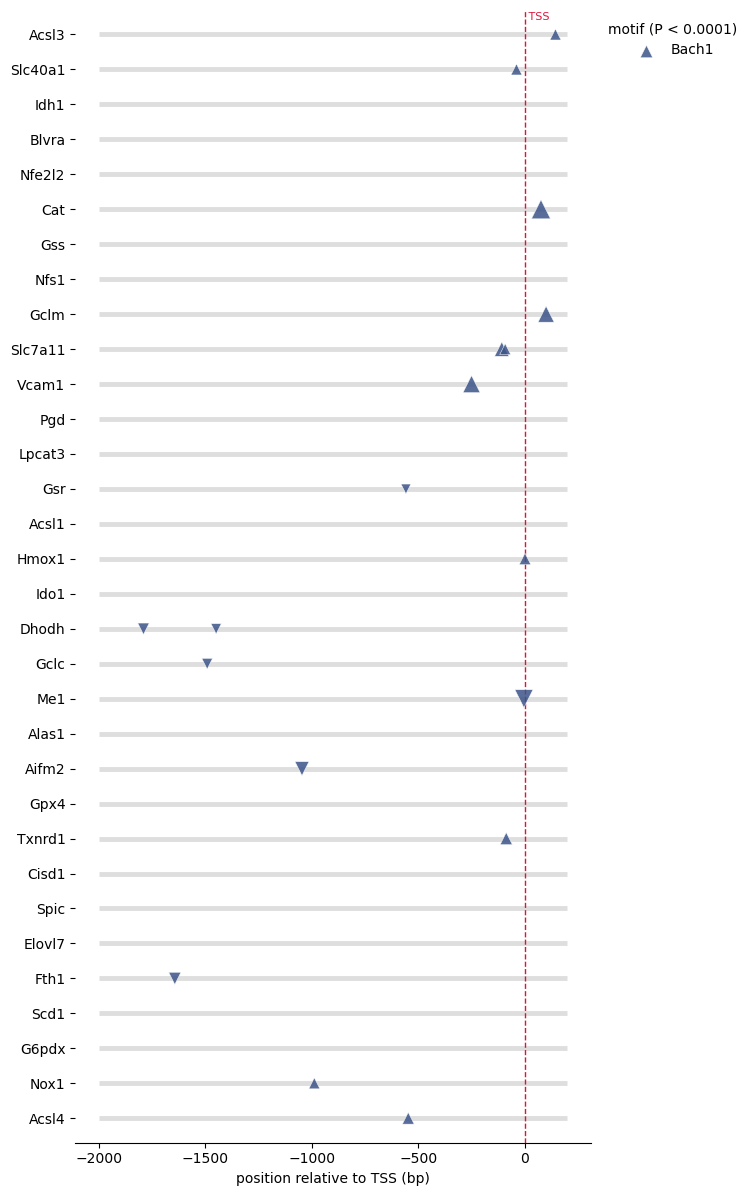

In [16]:
#| label: spicnetwork_Bach1_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network Bach1 Motifs Map"
#| output: asis
#| column: page

# Same 30 promoters, scanned with the Bach1 matrix.
hits_SpiCnet_Bach1motif = scan(["Bach1"], genes=["Spic","Nfe2l2", "Blvra",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1", "Hmox1", "Noq1"], name='SpiC_network_Bach1motif', FASTA = PROMOTER_FASTA)             

graph_SpiCnet_Bach1motif = sitemap(hits_SpiCnet_Bach1motif, name="SpiC_network_Bach1motif")

In [17]:
#| label: spicnetwork_bach1_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network Bach1 Motifs Table"
#| output: asis

# Genomic coordinates for the Bach1 hits in the SpiC-network promoters.
spic_network_Bach1motif_table = process_motif_hits("SpiC_network_Bach1motif", hits_SpiCnet_Bach1motif, gtf_sub)
spic_network_Bach1motif_table


,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promoter,end_motif_pos_promoter,Pval,sig,Chromosome,Chromosome_Strand,TSS_chromosomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Acsl3,NM_001033606.3,AGCTGCGTCAGGGT,138,151,6.300000e-05,4.203,NC_000067.7,+,78635600,138,78635738-78635751,+
1,Slc40a1,NM_016917.2,TGCTCTCTCAAGCT,-45,-32,6.300000e-05,4.203,NC_000067.7,-,45964754,-32,45964786-45964799,-
2,Cat,NM_009804.2,TGCTGTCTCACGTT,70,83,8.600000e-07,6.063,NC_000068.8,-,103315498,70,103315415-103315428,-
3,Gclm,NM_008129.4,TGCTTAGTCATTGT,94,107,5.500000e-06,5.259,NC_000069.7,+,122039206,94,122039300-122039313,+
4,Slc7a11,NM_011990.2,AGCTGAGTAATGTT,-114,-101,1.400000e-05,4.841,NC_000069.7,-,50398062,-101,50398163-50398176,-
5,Slc7a11,NM_011990.2,CGCTTTCTCAAGCT,-98,-85,6.500000e-05,4.184,NC_000069.7,-,50398062,-85,50398147-50398160,-
6,Vcam1,NM_011693.3,TACTGACTCACATT,-256,-243,3.000000e-06,5.520,NC_000069.7,-,115923337,-243,115923580-115923593,-
7,Gsr,NM_010344.4,CACCGAGTTAAAGT,-564,-551,1.000000e-04,4.000,NC_000074.7,+,34143266,-551,34142702-34142715,-
8,Hmox1,NM_010442.2,TGCTCGCTCACGGT,-5,8,5.100000e-05,4.293,NC_000074.7,+,75820246,0,75820241-75820254,+
9,Dhodh,NM_020046.3,TACTGAGTAAAACT,-1796,-1783,5.300000e-05,4.274,NC_000074.7,-,110335305,-1783,110337088-110337101,+


#### Bach1 Regulation of SpiC and Nfe2l2, Nqo1 and Hmox1 as reference

5 promoters, 1 matrices, 2 sites at P < 0.0001


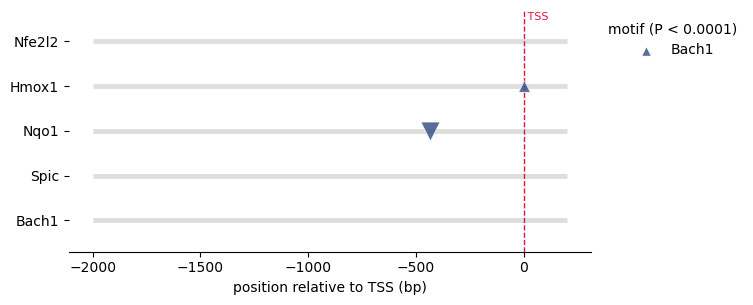

In [18]:
#| label: bach1_crossregulation_motifs_map
#| code-fold: true
#| code-summary: "Bach1 Motifs in the SpiC, Nfe2l2, Bach1, Hmox1 and Nqo1 Promoters"
#| output: asis
#| column: page

# Bach1 matrix over the three TF promoters plus Hmox1 and Nqo1 as positive controls.
hits_TFprom_Bach1motif = scan(["Bach1"], genes=["Spic", "Nfe2l2", "Bach1", "Hmox1", "Nqo1"], name="TFpromoters_Bach1motif", FASTA =  PROMOTER_FASTA)             

graph_TFprom_Bach1motif = sitemap(hits_TFprom_Bach1motif, name="TFpromoters_Bach1motif")

In [19]:
#| label: bach1_crossregulation_motifs_table
#| code-fold: true
#| code-summary: "Bach1 Motifs in the SpiC, Nfe2l2, Bach1, Hmox1 and Nqo1 Promoters Table"
#| output: asis

# Genomic coordinates for the Bach1 hits in the three TF promoters plus the controls.
TFprom_Bach1motif_table = process_motif_hits("TFpromoters_Bach1motif", hits_TFprom_Bach1motif, gtf_sub)
TFprom_Bach1motif_table


,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promoter,end_motif_pos_promoter,Pval,sig,Chromosome,Chromosome_Strand,TSS_chromosomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Hmox1,NM_010442.2,TGCTCGCTCACGGT,-5,8,0.000055,4.261,NC_000074.7,+,75820246,0,75820241-75820254,+
1,Nqo1,NM_008706.5,TGCCGACTCACTGT,-440,-427,0.000001,5.982,NC_000074.7,-,108129837,-427,108130264-108130277,+


#### Further investigation of SpiC Bach1 regulation

Bach1 is well detailed in being a negative regulator of SpiC, however direct evidence is not clear in the articles:

1 - https://www.cell.com/immunity/fulltext/S1074-7613(26)00273-6

2 - https://www.sciencedirect.com/science/article/pii/S0092867414002761?via%3Dihub

Recent articles try to access the binding region to the promoter.

1 - Analysis of binding sites (https://www.nature.com/articles/ni.3024#Sec27)

2 - And a ChIP-seq in biorxiv and confirmed promoter and Bach1 direct negative regulation (https://www.biorxiv.org/content/10.1101/2021.08.25.457658v1)

Show that the motif is way down the promoter region -39kb and -41kb distance from the gene.

1 promoters, 1 matrices, 8 sites at P < 0.0001


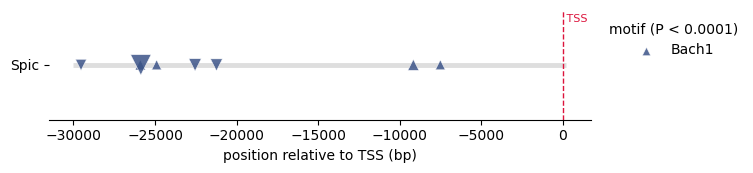

In [20]:
#| label: 5kb_Spic
#| code-fold: true
#| code-summary: "SpiC 5kb"
#| output: asis

# five_end(): collapses each interval to its single TSS coordinate (strand-aware --
#             gene Start on +, gene End on -), giving a 1bp interval at the TSS.
# .slack({"5": 2000, "3": 200}): extends that TSS point strand-aware:
#             2000bp toward the 5' side (upstream) and 200bp toward the 3' side
#             (downstream), so the result is your -2000/+200 promoter window
#             regardless of which genomic strand the gene is on.
prom_5kb = gtf_sub.five_end().slack({"5": 30000, "3": 200}) 
prom_5kb[['gene','transcript_id','Start', 'End', 'Strand']]                            

seqs_5kb = pr.get_sequence(prom_5kb, path=FA_v27)                        # Based on the coordinates identified before, we get the sequences from the reference genome
#get_sequence is also strand-aware and reverse-complements the minus strand

df_5kb                 = seqs_5kb.to_frame(name="DNA_Sequence")   # Convert the extracted sequences into a dataframe
df_5kb["Gene_Name"]    = prom_5kb.df['gene']                 # Attach gene names for use in the FASTA headers
df_5kb["TranscriptID"] = prom_5kb.df["transcript_id"]             # Attach transcript IDs for use in the FASTA headers

with open(PROMOTER_FASTA_5kb, "w") as file:
    for index, row in df_5kb.iterrows():
        # Combine your metadata into a single header line
        header = f">{row['Gene_Name']}|{row['TranscriptID']}"
        
        # Write the header and the sequence
        file.write(f"{header}\n")
        file.write(f"{row['DNA_Sequence']}\n")

hits_TFprom_Bach1motif = scan(["Bach1"], genes=["Spic"], name="TFpromoters5kb_Bach1motif", FASTA = PROMOTER_FASTA_5kb)             

graph_TFprom_Bach1motif = sitemap(hits_TFprom_Bach1motif, name="TFpromoters30kb_Bach1motif")

1 promoters, 1 matrices, 1 sites at P < 1e-05


/tmp/ipykernel_1441834/4127993558.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,


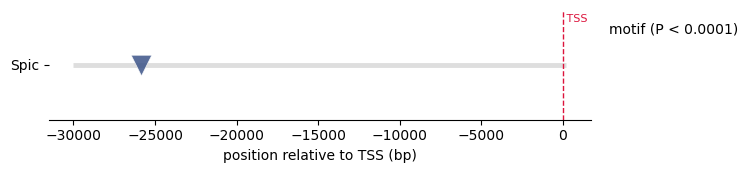

In [21]:
#| label: 5kb_Spic_lowerpval
#| code-fold: true
#| code-summary: "SpiC 5kb"
#| output: asis


hits_TFprom_Bach1motif_lowerpval = scan(["Bach1"], genes=["Spic"], name="TFpromoters30kb_pval05_Bach1motif", FASTA = PROMOTER_FASTA_5kb, pval=1e-5)             

graph_TFprom_Bach1motif = sitemap(hits_TFprom_Bach1motif_lowerpval, name="TFpromoters30kb_pval05_Bach1motif")

In SpiC, this not originated did not obtained further motifs in the expected regions, which is strange since they are well identified. The promoter may be shifted from the defined positions of the paper, has in the papers is from exon difference, not TSS. 

Itoh-Nakadai et al. (Nat Immunol 2014, 15:1171-1180) report Bach binding at two upstream Spic regions, drawn in Supplementary Fig. 6a as arrows at -39 kb and -41 kb. The figure is a schematic: it gives no sequences and no exact coordinates. The only precise record of those regions is the ChIP-qPCR primer pairs in Supplementary Table 12.

So the regions were locate by searching for the primers in our the promoter sequence window, then express the result relative to our own TSS. The labels "-39kb" and "-41kb" are kept as names (they identify which region the paper meant) but the positions we print are measured, not inherited -- the two disagree, because the paper's reference TSS is not the one in NM_011461.3.

Spic -39kb:  -25911 ..  -25816 bp (95 bp, midpoint -25.9 kb)
Spic -41kb:  -29524 ..  -29442 bp (82 bp, midpoint -29.5 kb)


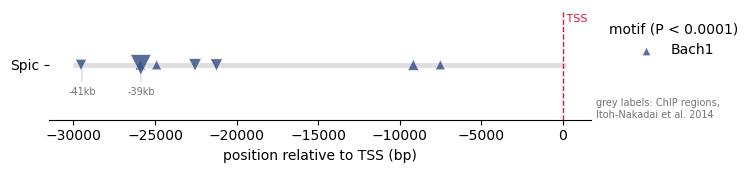

In [37]:
#| label: 5kb_Spic_marked
#| code-fold: true
#| code-summary: "Site map figure function, with published ChIP regions"
#| output: asis

# Published ChIP-qPCR regions to mark on the site map, as {gene: {label: (fwd, rev)}}.
# Primers from Itoh-Nakadai et al. 2014 (Nat Immunol 15:1171-1180), Suppl. Table 12;
# Suppl. Fig. 6a labels these regions -39kb and -41kb. Those labels are kept as
# names only -- the marks are placed where the primers actually land in our window,
# which is not where the labels say (their reference TSS is not ours).
CHIP_REGIONS = {"Spic": {"-39kb": ("GTTCTCAGGCAGCCTCCTC", "TTGCTTACTCATGGCTCGTG"),
                         "-41kb": ("GTCCCCAGGCATGAGAAAC", "GCAATGCCAGGCTAGTTCTT")}}

CHIP_SOURCE = "Itoh-Nakadai et al. 2014"


def sitemap_marked(hits, name=None, pval=PVAL, MOTIF_COLORS=MOTIF_COLORS,
                   chip=None, fasta=PROMOTER_FASTA):
    """Map motif sites along each promoter, positions relative to the TSS.

    hits  the DataFrame returned by scan(); its .attrs['scan_path'] is re-read to
          recover the 'limit' rows, so promoters with no site still get a lane.
    chip  optional {gene: {label: (fwd_primer, rev_primer)}}; each amplicon is
          located in `fasta` and labelled below that gene's lane.
    """

    path = Path(hits.attrs["scan_path"])
    lim  = (pd.read_csv(path, sep="\t", comment=";").query("ft_type == 'limit'")
              .drop_duplicates("#seq_id").set_index("#seq_id"))

    h = hits.assign(tss_pos=hits[["start", "end"]].mean(axis=1) + TSS_OFFSET,
                    logp=-np.log10(hits["Pval"]))
    ypos   = {s: i for i, s in enumerate(lim.index)}
    colors = {m: MOTIF_COLORS.get(m, "0.4") for m in h["ft_name"].unique()}

    fig, ax = plt.subplots(figsize=(9, 0.33 * len(lim) + 1.5))
    ax.hlines(range(len(lim)), lim["start"] + TSS_OFFSET, lim["end"] + TSS_OFFSET,
              color="0.87", lw=3.5, zorder=1)

    # Published ChIP regions, located by their primers and labelled below their own
    # lane. The amplicons are 82-95 bp, far under a pixel at this scale, so the
    # position is carried by the leader line rather than by a drawn span.
    if chip:
        rc = lambda s: s.translate(str.maketrans("ACGT", "TGCA"))[::-1]
        records = {b.split("\n")[0].split()[0]: "".join(b.split("\n")[1:]).upper()
                   for b in Path(fasta).read_text().split(">") if b.strip()}
        for gene, pairs in chip.items():
            seq_id = next((s for s in lim.index
                           if s.lstrip(">").split("|")[0] == gene), None)
            if seq_id is None:
                raise ValueError(f"{gene}: no lane matches. Lanes: {list(lim.index)}")
            seq, y = records[seq_id.lstrip(">")], ypos[seq_id]
            origin = len(seq) - TSS_OFFSET
            for label, pair in pairs.items():
                # One primer of each pair matches the stored strand, the other its
                # complement; the amplicon spans their outer edges.
                edges = []
                for p in pair:
                    i = max(seq.find(p), seq.find(rc(p)))
                    edges += [i, i + len(p)]
                if min(edges) < 0:
                    raise ValueError(f"{gene} {label}: primer absent from the "
                                     f"{len(seq)} bp record -- wrong FASTA?")
                s, e = min(edges) - origin, max(edges) - origin
                mid = (s + e) / 2
                # Below the lane, clear of the downward 'v' markers.
                ax.annotate(label, xy=(mid, y), xytext=(0, -22),
                            textcoords="offset points", ha="center",
                            fontsize=7, color="0.45",
                            arrowprops=dict(arrowstyle="-", lw=0.5, color="0.7"))
                print(f"{gene} {label}: {s:+7d} .. {e:+7d} bp "
                      f"({e - s} bp, midpoint {mid/1000:+.1f} kb)")

    # Size scales with significance from the threshold up; label once per motif,
    # on the direct strand, so the legend shows colour rather than colour x strand.
    for (motif, strand), g in h.groupby(["ft_name", "strand"]):
        ax.scatter(g["tss_pos"], g["#seq_id"].map(ypos),
                   marker="v" if strand == "R" else "^",
                   s=50 + 200 * (g["logp"] + np.log10(pval)) / 3,
                   color=colors[motif], zorder=3, alpha=0.85,
                   edgecolors="white", linewidths=0.4,
                   label=motif if strand == "D" else None)

    ax.axvline(0, color="crimson", lw=1, ls="--", zorder=2)
    ax.text(0, -0.65, " TSS", color="crimson", va="top", fontsize=8)
    ax.set_yticks(range(len(lim)))
    ax.set_yticklabels([s.lstrip(">").split("|")[0] for s in lim.index], fontsize=10)
    ax.set_ylim(-0.7, len(lim) - 0.3); ax.invert_yaxis()
    ax.set_xlabel("position relative to TSS (bp)")
    ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,
              markerscale=0.8, loc="upper left", bbox_to_anchor=(1.01, 1),
              frameon=False)
    # Attribution once, in the margin under the legend, rather than per label.
    if chip:
        ax.text(1.01, 0.0, f"grey labels: ChIP regions,\n{CHIP_SOURCE}",
                transform=ax.transAxes, fontsize=7, color="0.45",
                va="bottom", ha="left")
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout(rect=[0, 0, 0.85, 1])

    fig_path = SCAN_DIR / f"sitemap_{name}.svg"
    fig.savefig(fig_path)

    return fig


graph_TFprom30kb_Bach1motif_SpIC = sitemap_marked(
    hits_TFprom_Bach1motif,
    name="TFpromoters30kb_Bach1motif_SpIC",
    chip=CHIP_REGIONS,
    fasta="/srv/ext_home/ssalazar/projects/GIMM_projects/"
        "DNA_018_PromotorSeq_MotifFinder/Results/promoters_sequences_5kb.fasta",
)

Spic -39kb:  -25911 ..  -25816 bp (95 bp, midpoint -25.9 kb)
Spic -41kb:  -29524 ..  -29442 bp (82 bp, midpoint -29.5 kb)


/tmp/ipykernel_1441834/3596675973.py:90: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,


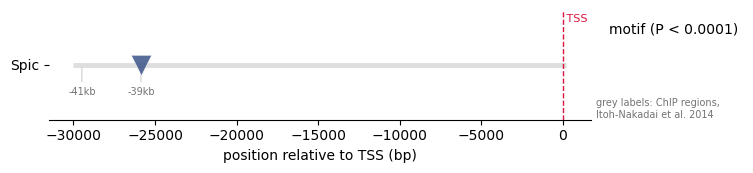

In [27]:
#| label: 5kb_Spic_lowerpval_marked
#| code-fold: true
#| code-summary: "SpiC 5kb"
#| output: asis

graph_TFprom30kb_Bach1motif_SpIC_pval05 = sitemap_marked(
    hits_TFprom_Bach1motif_lowerpval,
    name="TFpromoters30kb_Bach1motif_SpIC_pval05",
    chip=CHIP_REGIONS,
    fasta="/srv/ext_home/ssalazar/projects/GIMM_projects/"
        "DNA_018_PromotorSeq_MotifFinder/Results/promoters_sequences_5kb.fasta",
)

### All Transcription Factors

#### SpiC, Nfe2l2, Bach1 Cross-regulation 

3 promoters, 4 matrices, 7 sites at P < 0.0001


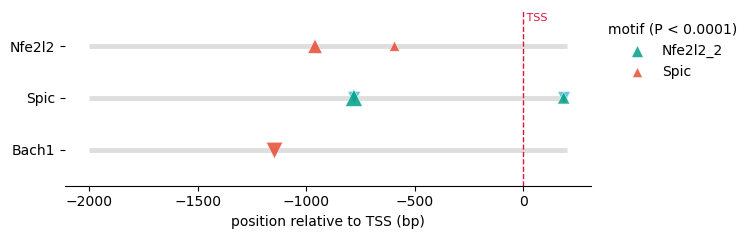

In [28]:
#| label: FT_crossregulation_motifs_map
#| code-fold: true
#| code-summary: "SpiC, Nfe2l2 and Bach1 Cross Regulation Motifs Map"
#| output: asis


# All four matrices over the three TF promoters, to look for cross-regulation.
hits_TFprom_allmotifs = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Spic", "Nfe2l2", "Bach1"], name="TFpromoters_all_TFs", FASTA = PROMOTER_FASTA)             

graph_TFprom_allmotifs = sitemap(hits_TFprom_allmotifs, name="TFpromoters_all_TFs")

In [29]:
#| label: FT_crossregulation_motifs_table
#| code-fold: true
#| code-summary: "SpiC, Nfe2l2 and Bach1 Cross Regulation Motifs Table"
#| output: asis

# Genomic coordinates for the cross-regulation hits.
TFprom_allmotifs_table = process_motif_hits("TFpromoters_all_TFs", hits_TFprom_allmotifs, gtf_sub)
TFprom_allmotifs_table

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promoter,end_motif_pos_promoter,Pval,sig,Chromosome,Chromosome_Strand,TSS_chromosomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Nfe2l2,NM_010902.5,AAATAGAGTAAGTA,-966,-953,0.000014,4.867,NC_000068.8,-,75534860,-953,75535813-75535826,-
1,Nfe2l2,NM_010902.5,CAAATCAGGGAGTG,-600,-587,0.000090,4.044,NC_000068.8,-,75534860,-587,75535447-75535460,-
2,Spic,NM_011461.3,AACTTCTGAGTCAT,-787,-774,0.000003,5.495,NC_000076.7,-,88518885,-774,88519659-88519672,-
3,Spic,NM_011461.3,ATGACTCAGAA,-784,-774,0.000029,4.536,NC_000076.7,-,88518885,-774,88519659-88519669,+
4,Spic,NM_011461.3,TAAAGCTGAATCAT,179,192,0.000039,4.407,NC_000076.7,-,88518885,179,88518693-88518706,-
5,Spic,NM_011461.3,ATGATTCAGCT,182,192,0.000032,4.489,NC_000076.7,-,88518885,182,88518693-88518703,+
6,Bach1,NM_007520.2,AAAATGAGGAAGGA,-1154,-1141,0.000004,5.370,NC_000082.7,+,87495842,-1141,87494688-87494701,-


#### Motifs of SpiC, Nfe2l2 and Bach1 in the assumed SpiC Network

32 promoters, 4 matrices, 93 sites at P < 0.0001


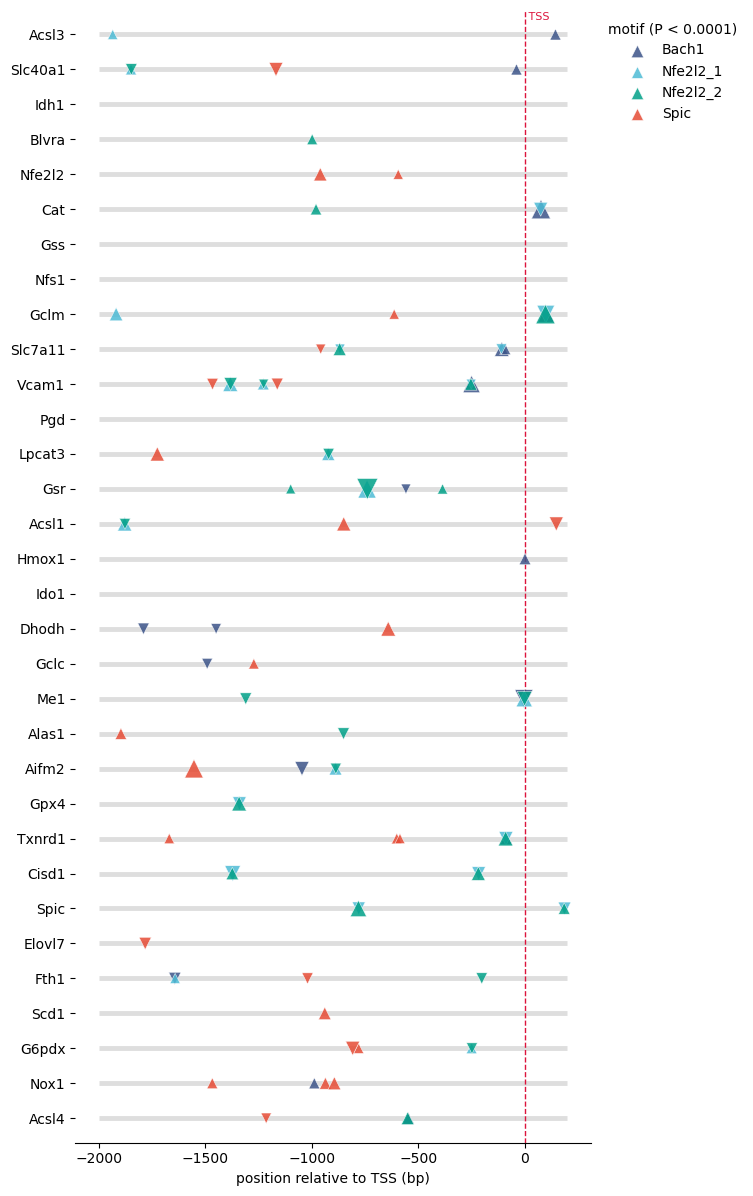

In [30]:
#| label: spicnetwork_alltfs_motifs_map
#| code-fold: true
#| code-summary: "SpiC Network SpiC, Nfe2l2 and Bach1 Motifs Map"
#| output: asis
#| column: page

# All four matrices over the 30 network promoters: the full site inventory.
hits_SpiCnet_allmotifs = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Spic","Nfe2l2", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"], name='SpiC_network_all_TFs', FASTA = PROMOTER_FASTA)             

graph_SpiCnet_allmotifs = sitemap(hits_SpiCnet_allmotifs, name="SpiC_network_all_TFs")

In [31]:
#| label: spicnetwork_alltfs_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network SpiC, Nfe2l2 and Bach1 Motifs Table"
#| output: asis

# Genomic coordinates for the full network inventory.
spicnet_allmotifs_table = process_motif_hits("SpiC_network_all_TFs", hits_SpiCnet_allmotifs, gtf_sub)
spicnet_allmotifs_table

,Gene_Name,TranscriptID,Motif_Sequence_Found,start_motif_pos_promoter,end_motif_pos_promoter,Pval,sig,Chromosome,Chromosome_Strand,TSS_chromosomal_localization,dist_to_TSS,motif_genomic_localization,motif_genomic_strand
0,Acsl3,NM_001033606.3,GTGAGTCATCA,-1939,-1929,0.000091,4.041,NC_000067.7,+,78635600,-1929,78633661-78633671,+
1,Acsl3,NM_001033606.3,AGCTGCGTCAGGGT,138,151,0.000063,4.203,NC_000067.7,+,78635600,138,78635738-78635751,+
2,Slc40a1,NM_016917.2,GTGACTGAGCT,-1853,-1843,0.000067,4.171,NC_000067.7,-,45964754,-1843,45966597-45966607,-
3,Slc40a1,NM_016917.2,CATAGCTCAGTCAC,-1853,-1840,0.000054,4.271,NC_000067.7,-,45964754,-1840,45966594-45966607,+
4,Slc40a1,NM_016917.2,AAAATGGGGTAGTA,-1174,-1161,0.000020,4.689,NC_000067.7,-,45964754,-1161,45965915-45965928,+
...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,Nox1,NM_172203.2,TTAAAGAGGAACTT,-942,-929,0.000046,4.340,NC_000086.8,-,133012603,-929,133013532-133013545,-
89,Nox1,NM_172203.2,TAAACGAGGAAGTC,-900,-887,0.000028,4.558,NC_000086.8,-,133012603,-887,133013490-133013503,-
90,Acsl4,NM_207625.2,AAAAAGAAGAAGAA,-1220,-1207,0.000080,4.095,NC_000086.8,-,141173531,-1207,141174738-141174751,+
91,Acsl4,NM_207625.2,TTTTGCTGAGTGAC,-556,-543,0.000031,4.511,NC_000086.8,-,141173531,-543,141174074-141174087,-


# **Conclusion**

In [32]:
#| label: conclusion
#| echo: false
#| output: asis

# Counts are read from the objects already in memory so the text cannot drift if the
# report is re-run on a different gene panel; a numberless sentence is used as fallback.
try:
    n_requested = len(set(genes))
    n_found     = len(gtf_sub.df["gene"].unique())
    n_promoters = len(prom_2kb.df)
    found_txt   = (f"{n_found} of the {n_requested} requested genes were recovered "
                   f"and {n_promoters} promoter windows extracted")
except Exception:
    found_txt = "the requested genes were recovered and their promoter windows extracted"

try:
    n_spic = len(hits_SpiCnet_SpiCmotif)
    n_all  = len(hits_SpiCnet_allmotifs)
    n_tf   = len(hits_TFprom_allmotifs)
    if n_all:
        sites_txt = (f"Scanning the network promoters with all four matrices returned "
                     f"{n_all} sites at <i>P</i> &lt; {PVAL:g}, of which {n_spic} were "
                     f"calls of the SpiC matrix; the scan restricted to the "
                     f"<i>Spic</i>, <i>Nfe2l2</i> and <i>Bach1</i> promoters returned "
                     f"{n_tf} sites.")
    else:
        sites_txt = (f"No site passed the <i>P</i> &lt; {PVAL:g} threshold in any "
                     f"promoter, which is itself the result: at this threshold and with "
                     f"these matrices the panel carries no detectable binding site.")
except Exception:
    sites_txt = ("Sites passing the significance threshold are listed in the tables "
                 "above.")

display(HTML(f"""
<p>This report establishes a reproducible, in-notebook workflow for defining promoter
regions and scanning them for transcription-factor binding motifs, in support of the
SpiC regulatory analysis. Coordinates were taken from the curated RefSeq annotation of
the <i>Mus musculus</i> GRCm39 assembly (GCF_000001635.27), replacing the
Ensembl/GENCODE annotation used in the previous report: the automated selection of a
canonical transcript placed the annotated TSS of several genes upstream of the
functional promoter, which was noticed when the Ensembl-anchored window for
<i>Nqo1</i> failed to contain its published ARE region.</p>

<p>Restricting the annotation to RefSeq Select transcripts gives one canonical
transcript per gene, so {found_txt} without duplication; <i>Scd5</i> has no mouse
counterpart in this assembly and is absent from the analysis. Each promoter was defined
strand-aware as &minus;2,000 bp to +200 bp around the TSS and written to FASTA.</p>

<p>The manual RSAT Web-form procedure of the earlier SOP was replaced by a local
<code>rsat-core</code> installation driven from this notebook, so the matrices, the
background model and the threshold are recorded in the report rather than in
screenshots. CIS-BP matrices were converted to count-like TRANSFAC blocks, the
first-order Markov background was estimated with <code>oligo-analysis</code> over the
complete promoter set rather than each gene subset, and both strands were scanned.
{sites_txt}</p>

<p>Hit positions were translated from promoter-relative coordinates back to genomic
coordinates and exported per scan, so each site can be inspected in a browser. </p>

<p><b>These are sequence-based predictions of binding potential:
they support, but do not establish, direct regulation.</b></p>
"""))


# **Methods**

## Condensed paragraph for the manuscript

Promoter regions were defined as −2,000 bp to +200 bp relative to the transcription
start site (TSS) of each gene's RefSeq Select transcript, based on the mouse genome
assembly GRCm39 (RefSeq annotation GCF_000001635.27; equivalent GenBank assembly
accession [GCA_000001635.9](https://identifiers.org/insdc.gca/GCA_000001635.9)). These
sequences were screened for SpiC, Nfe2l2 and Bach1 binding sites to assess the potential
for direct SpiC-mediated transcriptional regulation and for cross-regulation between the
three factors. The position weight matrices were retrieved from the CIS-BP database
(Lambert et al., 2019), build 3.10, *Mus musculus*: motif M03221_3.10 for SpiC,
M09222_3.10 and M10174_3.10 for Nfe2l2 and M10181_3.10 for Bach1.
Scanning was performed with *matrix-scan* from the Regulatory Sequence Analysis Tools
(RSAT) suite (Turatsinze et al., 2008), scanning both strands with a first-order Markov
background model estimated from the input promoter sequences, a pseudo-count of 1, and a
per-site p-value threshold of 1 x 10E-4.

## Promoter definition and sequence retrieval

Promoter sequences were defined from the *Mus musculus* GRCm39 reference assembly and
its curated RefSeq annotation (NCBI assembly GCF_000001635.27, annotation release 27),
using the genomic FASTA and GFF3 files distributed with that release. Annotation
records were read with `pyranges` and restricted to `mRNA` features carrying the
`RefSeq Select` tag, which retains a single curated representative transcript per gene;
this replaced the Ensembl/GENCODE annotation used previously, whose automated
canonical-transcript selection placed the annotated transcription start site (TSS) of
several genes upstream of the functional promoter. Each transcript interval was collapsed to its TSS in a
strand-aware manner (interval start on the plus strand, interval end on the minus
strand) and extended by 2,000 bp upstream and 200 bp downstream of that position, giving
a 2,201 bp promoter window per gene. Sequences were extracted from the reference FASTA
with `pyranges`, which reverse-complements minus-strand intervals, and written to a
single multi-FASTA file with headers combining the gene symbol and the RefSeq transcript
accession.

## Position-specific scoring matrices

Matrices were taken from the CIS-BP *Mus musculus* collection (build 3.10), obtained as
a bulk download rather than through the RSAT-bundled motif databases. One matrix was
used for SpiC (M03221_3.10), two for Nfe2l2 (M09222_3.10 and M10174_3.10) and one for
Bach1 (M10181_3.10). CIS-BP distributes these as position-wise base probabilities; each
column was multiplied by 100 to produce count-like values before conversion to TRANSFAC
format, so that the pseudo-count applied during scanning remained a small correction
rather than a substantial fraction of each column.

## Motif scanning

Scanning was performed with *matrix-scan* from the Regulatory Sequence Analysis Tools
(RSAT) suite (Turatsinze et al., 2008), run as a local `rsat-core` installation
(bioconda build 2025.04.04) called directly from this notebook, replacing the manual
Web-form procedure used previously. A first-order Markov background model was estimated
with RSAT *oligo-analysis* over dinucleotides (oligomer length 2) on a single strand,
computed once from the complete promoter set and reused for every scan, so that
*P*-values remain comparable across gene subsets and are not derived from a model fitted
to one or two sequences. The background was supplied to *matrix-scan* as a frequency
file. Scans were run on both strands with a pseudo-count of 1 on
the matrices and a background pseudo-frequency of 0.01, positions numbered from the end
of each sequence so that coordinates are expressed relative to the TSS, and sites were
retained at a per-site threshold of *P* < 1 x 10<sup>-4</sup>, with no correction for
multiple testing applied across promoters or across matrices. Both the per-sequence
limits and the site records were returned, so that promoters without a site above
threshold remain represented.

## Coordinate conversion and reporting

Promoter
coordinates reported by *matrix-scan* were shifted by 201 bp so that position 0
corresponds to the TSS base, with negative values upstream and positive values
downstream. The distance to the TSS was taken as the nearest site edge - the end
coordinate for entirely upstream sites, the start coordinate for entirely downstream
sites, and zero for sites spanning the TSS. Promoter-relative coordinates were then
converted back to chromosomal coordinates using the transcript TSS and strand, swapping
the interval edges on the minus strand, and the motif strand reported by *matrix-scan*
was combined with the transcript strand to give the genomic orientation of each site.
The resulting tables - gene symbol, transcript accession, matched sequence,
promoter-relative and chromosomal coordinates, distance to TSS, *P*-value and
significance - were exported per scan as comma-separated files. Site maps showing all
retained sites along each promoter relative to the TSS were drawn with `matplotlib` and
saved in vector SVG format.

## Software

Analyses were performed in Python 3.12 with `pyranges` 0.1.4, `pyfaidx` 0.9.0.4,
`pandas` 2.2.3, `numpy` 2.1.3 and `matplotlib` 3.10.3, and RSAT `rsat-core` 2025.04.04
(bioconda). The full environment is recorded in the Session Information section below.


# **Result Files**

In [33]:
#| label: result_files
#| echo: false
#| output: asis

# The folder is read at render time rather than listing filenames by hand: several
# outputs are named from a loop variable and would go stale the moment a scan is added.
_KIND = {".svg": "Vector figure", ".pdf": "Vector figure", ".png": "Raster figure",
         ".xlsx": "Statistics table", ".csv": "Data table", ".tsv": "Data table",
         ".ft": "RSAT matrix-scan output", ".txt": "RSAT matrix-scan output",
         ".fasta": "Sequence file", ".fa": "Sequence file"}

try:
    _files = sorted((f for f in Path(RESULTS).rglob("*")
                     if f.is_file() and not f.name.startswith(".")),
                    key=lambda f: str(f.relative_to(RESULTS)))
    _intro = ("<p>All figures are written in vector <code>.svg</code> format and all "
              "motif coordinate tables as <code>.csv</code> files, alongside the raw "
              "<code>.ft</code> feature tables written by <i>matrix-scan</i>. All code "
              "is stored in the internal ADA git repository "
              "<i>&lt;DNA_018_PromotorSeq_MotifFinder&gt;</i> that can be shared upon user request.</p>")

    if not _files:
        display(HTML(_intro + f"<p>No result files were found under "
                              f"<code>{RESULTS}</code>. The report was most likely "
                              f"rendered without re-executing the analysis.</p>"))
    else:
        _rows = []
        for f in _files:
            _rows.append(
                f"<tr><td><code>{f.relative_to(RESULTS)}</code></td>"
                f"<td>{_KIND.get(f.suffix.lower(), 'Other')}</td>"
                f"<td align='right'>{f.stat().st_size / 1024:,.1f} kB</td></tr>")

        display(HTML(
            _intro
            + f"<p>The {len(_files)} files below were read from <code>{RESULTS}</code>. "
              f"Figures are SVG, so all text in them stays editable for figure "
              f"assembly.</p>"
            + "<table><thead><tr><th>File</th><th>Contents</th>"
              "<th>Size</th></tr></thead><tbody>"
            + "".join(_rows) + "</tbody></table>"))

except Exception as _e:
    display(HTML(f"<p>The result folder could not be listed "
                 f"({type(_e).__name__}: {_e}).</p>"))

File,Contents,Size
background_sensitivity_discordant.csv,Data table,0.2 kB
background_sensitivity_summary.csv,Data table,0.3 kB
matrix_scan/chipmap_Spic.svg,Vector figure,22.9 kB
matrix_scan/motif_logo_Bach1.svg,Vector figure,188.2 kB
matrix_scan/motif_logo_Nfe2l2_1.svg,Vector figure,151.7 kB
matrix_scan/motif_logo_Nfe2l2_2.svg,Vector figure,164.0 kB
matrix_scan/motif_logo_Spic.svg,Vector figure,171.8 kB
matrix_scan/motif_matrices_Bachs.tf,Other,3.2 kB
matrix_scan/motif_matrices_SpiC_Nfe2l2_Bach1.tf,Other,1.9 kB
matrix_scan/scanmotif_Bachs_motifs_alternatives.ft,RSAT matrix-scan output,14.8 kB


# **Session Information**

In [34]:
#| label: session_information
#| echo: false

import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    session_info.show(html=False, dependencies=True)


-----
PIL                 11.2.1
matplotlib          3.10.3
numpy               2.1.3
pandas              2.2.3
pyfaidx             0.9.0.4
pyranges            0.1.4
session_info        v1.0.1
-----
anyio                       NA
arrow                       1.3.0
astroid                     3.3.9
asttokens                   NA
attr                        25.3.0
attrs                       25.3.0
babel                       2.17.0
brotli                      1.1.0
certifi                     2026.06.17
charset_normalizer          3.4.1
colorama                    0.4.6
comm                        0.2.2
cycler                      0.12.1
cython_runtime              NA
dateutil                    2.9.0.post0
debugpy                     1.8.14
decorator                   5.2.1
defusedxml                  0.7.1
executing                   2.1.0
fastjsonschema              NA
fqdn                        NA
idna                        3.10
ipykernel                   6.29.5
ipywidgets        

In [38]:
#| label: render_html
#| echo: false
#| output: false
#| message: false

##render html
os.system(f'quarto render "/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Notebooks/PromoterExtraction_adapted_with_rsatconda_refseqannotation.ipynb" --to html')


pandoc 
  to: html
  output-file: PromoterExtraction_adapted_with_rsatconda_refseqannotation.html
  standalone: true
  embed-resources: true
  section-divs: true
  html-math-method: mathjax
  wrap: none
  default-image-extension: png
  toc: true
  toc-depth: 5
  number-sections: true
  variables: {}
  
metadata
  document-css: false
  link-citations: true
  date-format: long
  lang: en
  title: DNA008 Report
  author: Sara Salazar (promoter retrieval adapted from Andre Barros work)
  date: last-modified
  editor: visual
  jupyter: python
  page-layout: article
  
Output created: PromoterExtraction_adapted_with_rsatconda_refseqannotation.html



0